# UTS Graf Sains Data

**Nama:** Kristian Bintang Marnaek Hutapea  
**NIM:** 23031554004  
**Kelas:** GSD 2023E

Notebook ini berisi proses, source code, visualisasi, dan output hasil eksekusi analisis RetailRocket.

## 1. Tujuan
Membuat graph `Visitor` dan `Item`, membangun VSM, menghitung similarity item, lalu membuat rekomendasi KNN dan mengevaluasinya secara temporal.

In [1]:
from pathlib import Path
import json
import pandas as pd

BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / 'output'
summary = json.loads((OUTPUT_DIR / 'summary.json').read_text(encoding='utf-8'))
print('Folder output:', OUTPUT_DIR)
print('Nama:', summary['student']['name'])
print('NIM:', summary['student']['nim'])

Folder output: output
Nama: Kristian Bintang Marnaek Hutapea
NIM: 23031554004


## 2. Pembagian data
Timestamp dikonversi dari Unix epoch milliseconds ke UTC. Training memakai 01 Mei sampai 20 Juli 2015, sedangkan testing memakai 21 Juli sampai 10 Agustus 2015. Batas akhir dibuat eksklusif agar tidak terjadi overlap.

In [2]:
print('Training:', summary['training_period'], summary['training_events'], 'event')
print('Testing :', summary['testing_period'], summary['testing_events'], 'event')
print('Training user dan item:', summary['training_users'], summary['training_items'])
print('Testing user dan item :', summary['testing_users'], summary['testing_items'])

Training: ['2015-05-01', '2015-07-20'] 1635266 event
Testing : ['2015-07-21', '2015-08-10'] 441425 event
Training user dan item: 830707 187985
Testing user dan item : 243247 98648


## 3. Komposisi event
Event `view`, `addtocart`, dan `transaction` akan dipetakan menjadi relationship `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT` pada Neo4j.

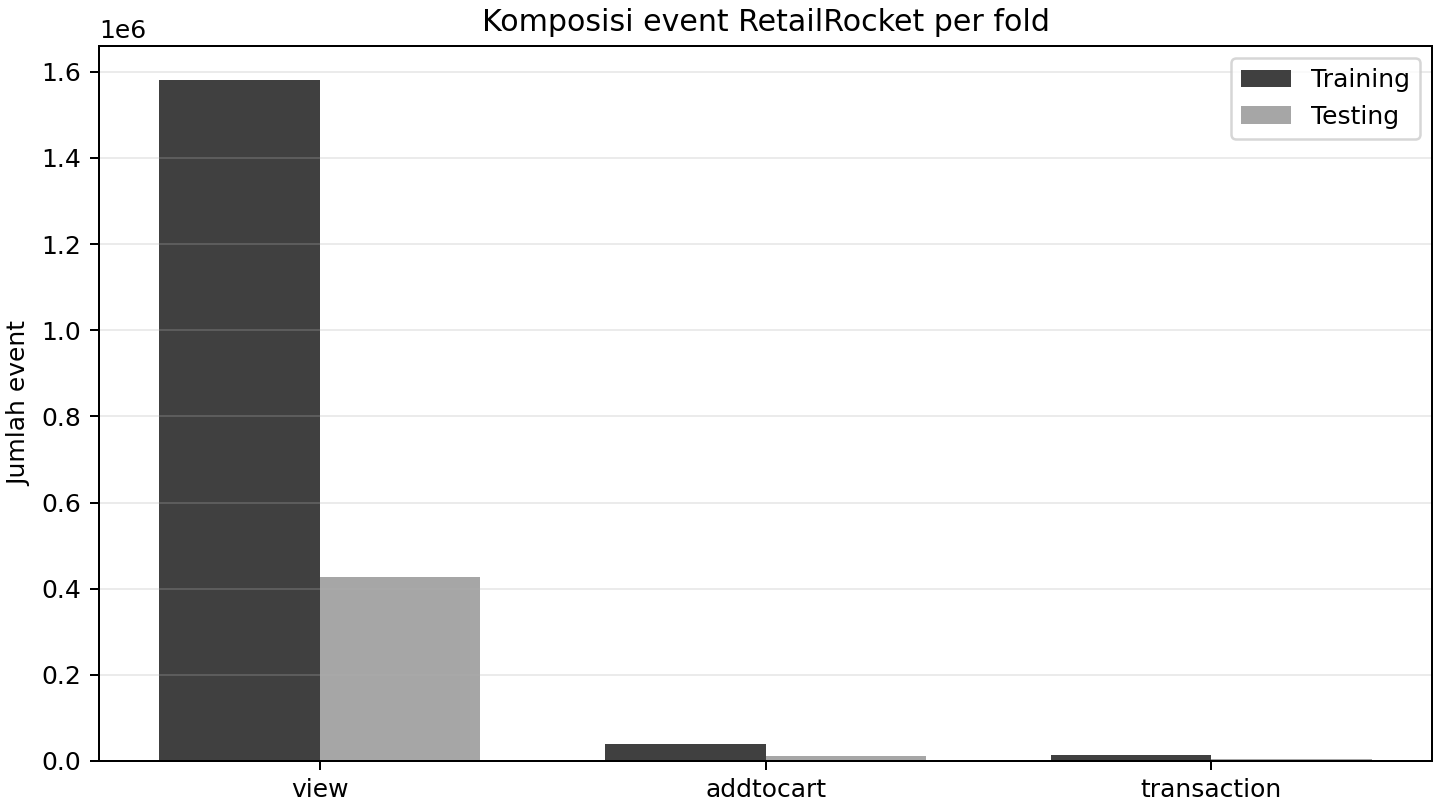

In [3]:
from IPython.display import Image, display
display(Image(filename='output/01_komposisi_event.png'))

## 4. VSM user
VSM user adalah matriks user-item dengan bobot `view=1`, `addtocart=3`, dan `transaction=5`. Karena graph penuh sangat besar, yang ditampilkan adalah subgraph sampel.

In [4]:
vsm = summary['vsm']
print('Shape VSM user:', tuple(vsm['user_vsm_shape']))
print('Pasangan user-item tidak nol:', vsm['nonzero_user_item_pairs'])
print('Density:', vsm['density'])
print('Rata-rata item per user:', round(vsm['mean_user_degree'], 2))

Shape VSM user: (830707, 187985)
Pasangan user-item tidak nol: 1266049
Density: 8.107359810123459e-06
Rata-rata item per user: 1.52


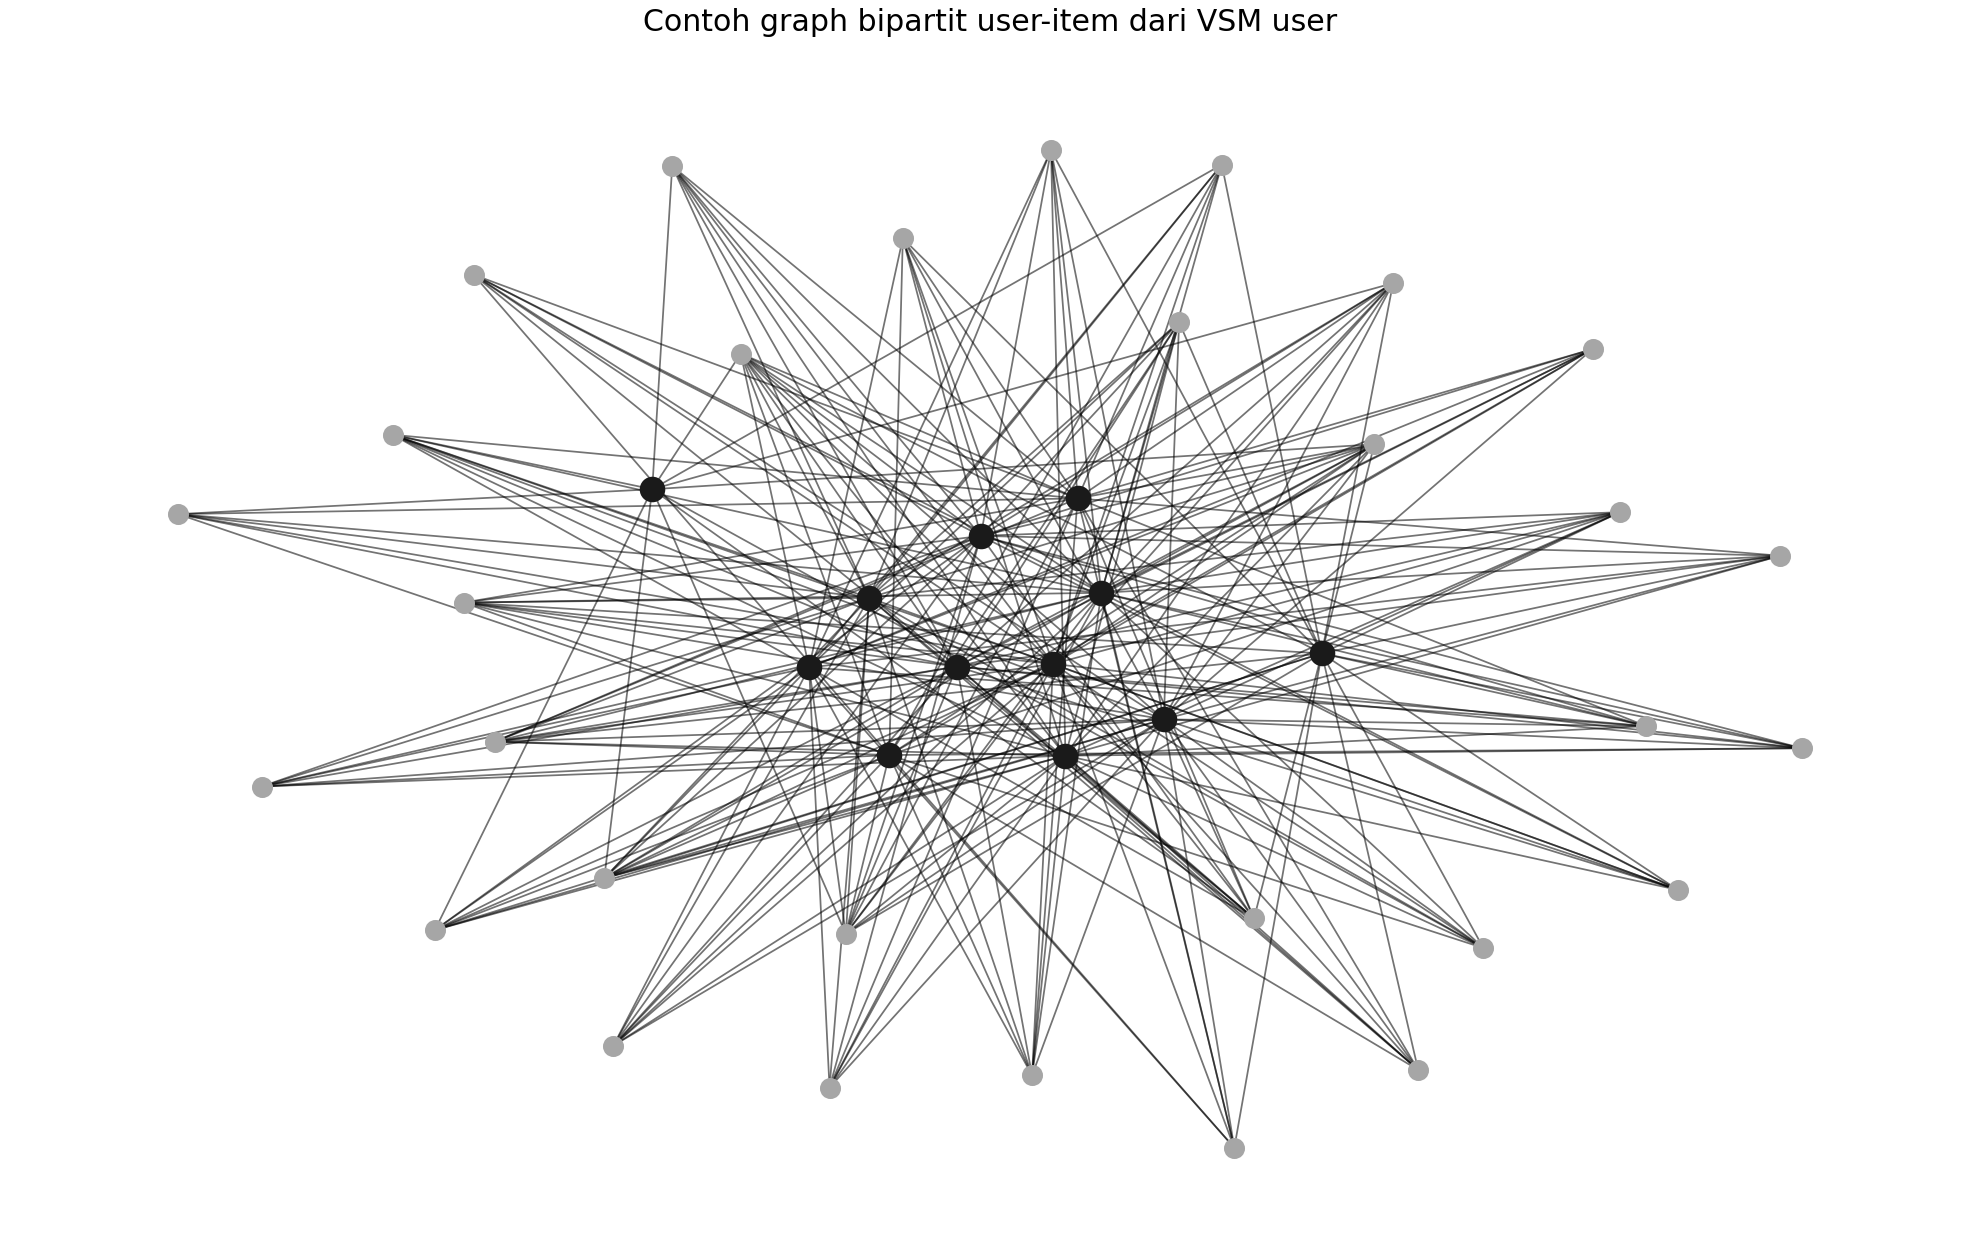

In [5]:
from IPython.display import Image, display
display(Image(filename='output/02_contoh_graph_bipartit_user_vsm.png'))

## 5. VSM item dan proyeksi
VSM item adalah transpose VSM user. Proyeksi item dipilih karena kandidat edge-nya lebih sedikit dibanding proyeksi user.

In [6]:
print('Shape VSM item:', tuple(vsm['item_vsm_shape']))
print('Kandidat edge proyeksi user:', vsm['candidate_user_projection_edges'])
print('Kandidat edge proyeksi item:', vsm['candidate_item_projection_edges'])
print('Proyeksi yang dipilih:', vsm['recommended_projection'])

Shape VSM item: (187985, 830707)
Kandidat edge proyeksi user: 34749684
Kandidat edge proyeksi item: 16149176
Proyeksi yang dipilih: item


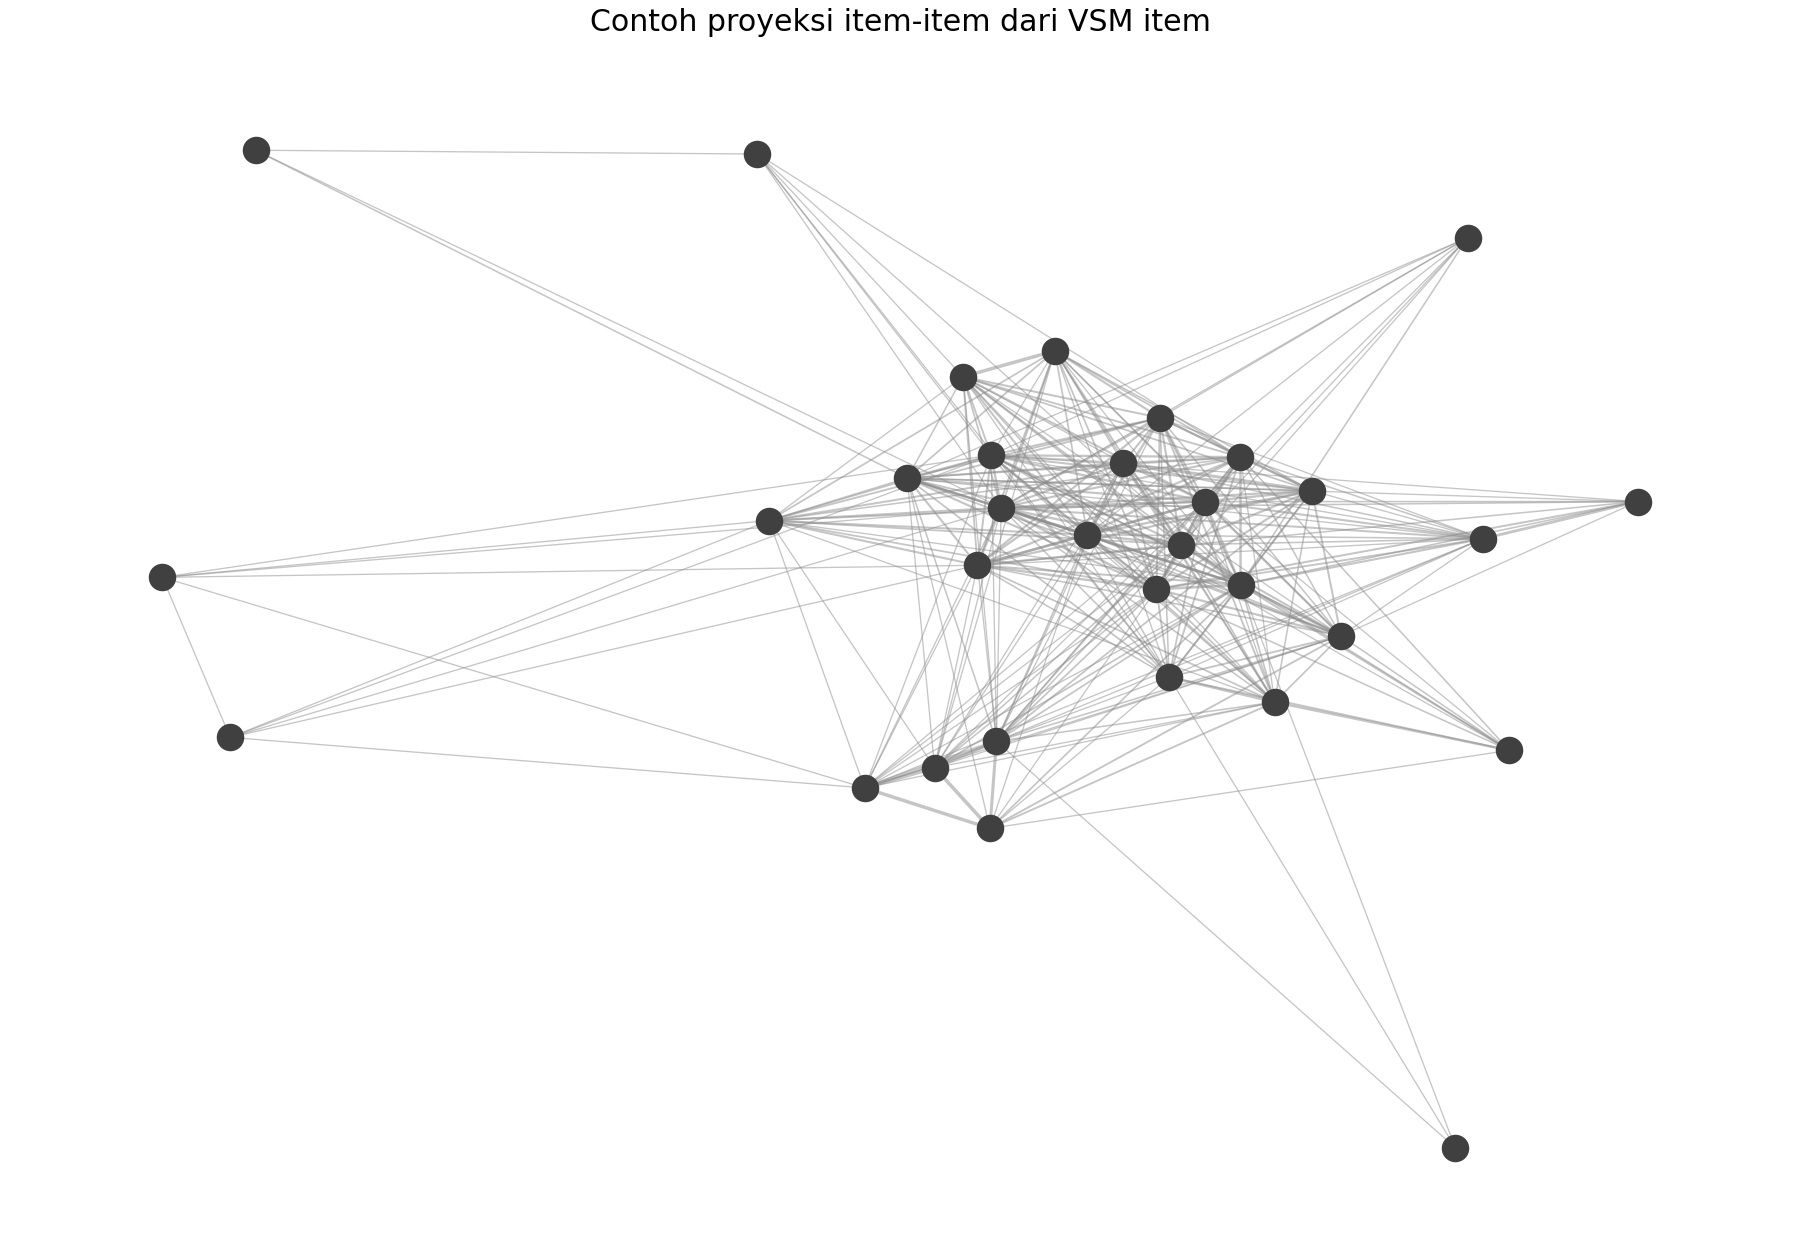

In [7]:
from IPython.display import Image, display
display(Image(filename='output/03_contoh_proyeksi_item_vsm.png'))

## 6. Similarity item
Cosine similarity dihitung pada VSM item. Item acuan adalah item `5411`, yaitu item yang paling sering muncul pada training.

In [8]:
pd.read_csv(OUTPUT_DIR / 'top5_item_similarity.csv')

reference_item,similar_item,cosine_similarity
5411,33030,0.14443843
5411,33956,0.11763925
5411,37807,0.10010426
5411,256242,0.09232622
5411,299052,0.07992012


## 7. Visualisasi graph sebelum dan sesudah similarity
Visual ini memakai subgraph kecil agar hubungan antar-item dapat dibaca. Graph pertama hanya berisi relasi event User ke Item. Graph kedua menambahkan edge `SIMILAR_TO` antar-item hasil cosine similarity.

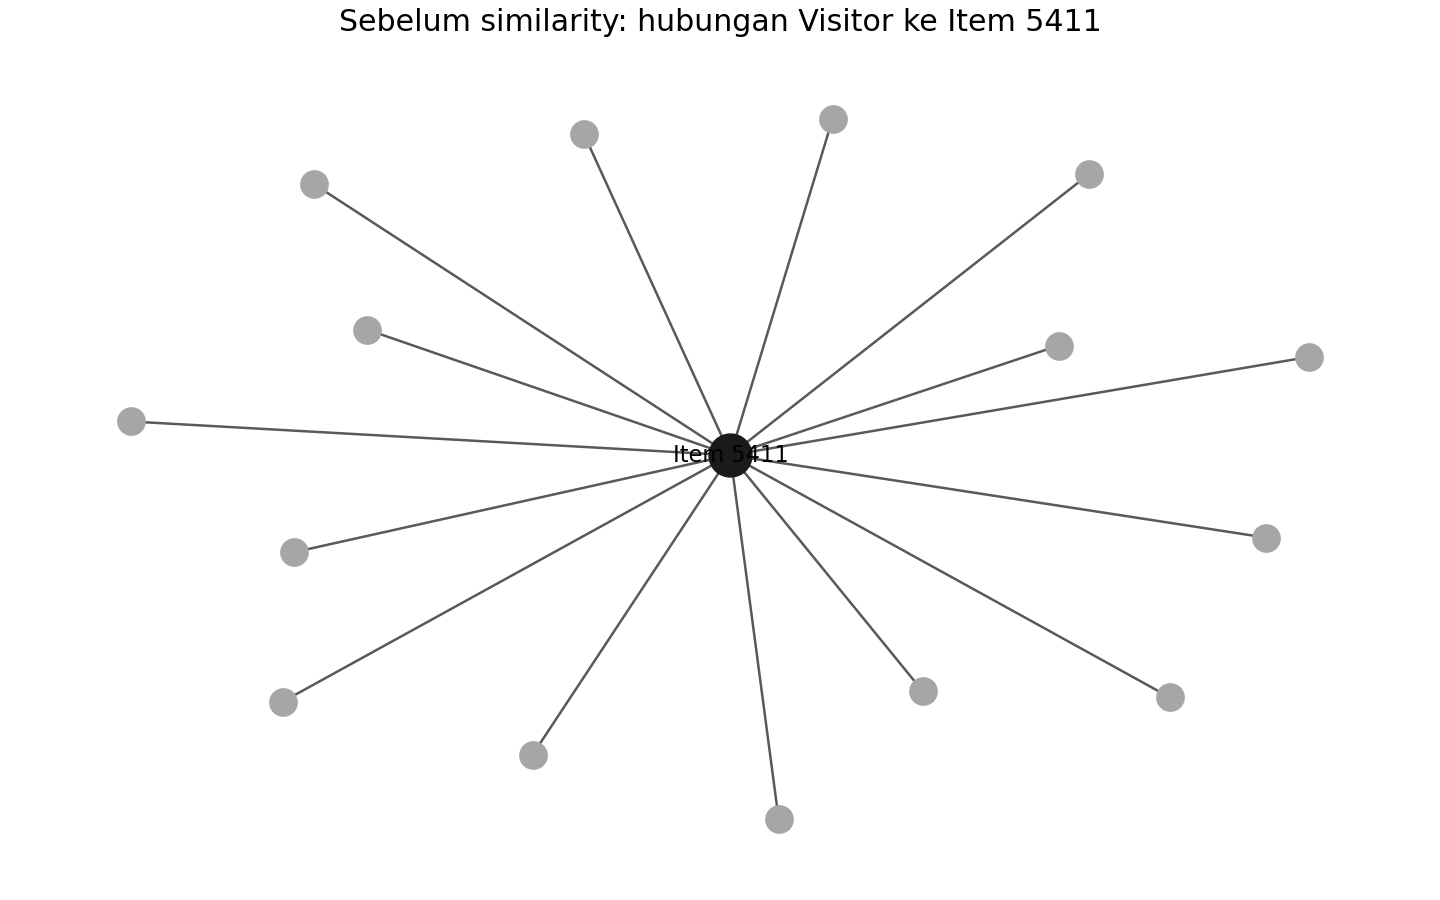

In [9]:
from IPython.display import Image, display
display(Image(filename='output/04_graph_sebelum_similarity.png'))

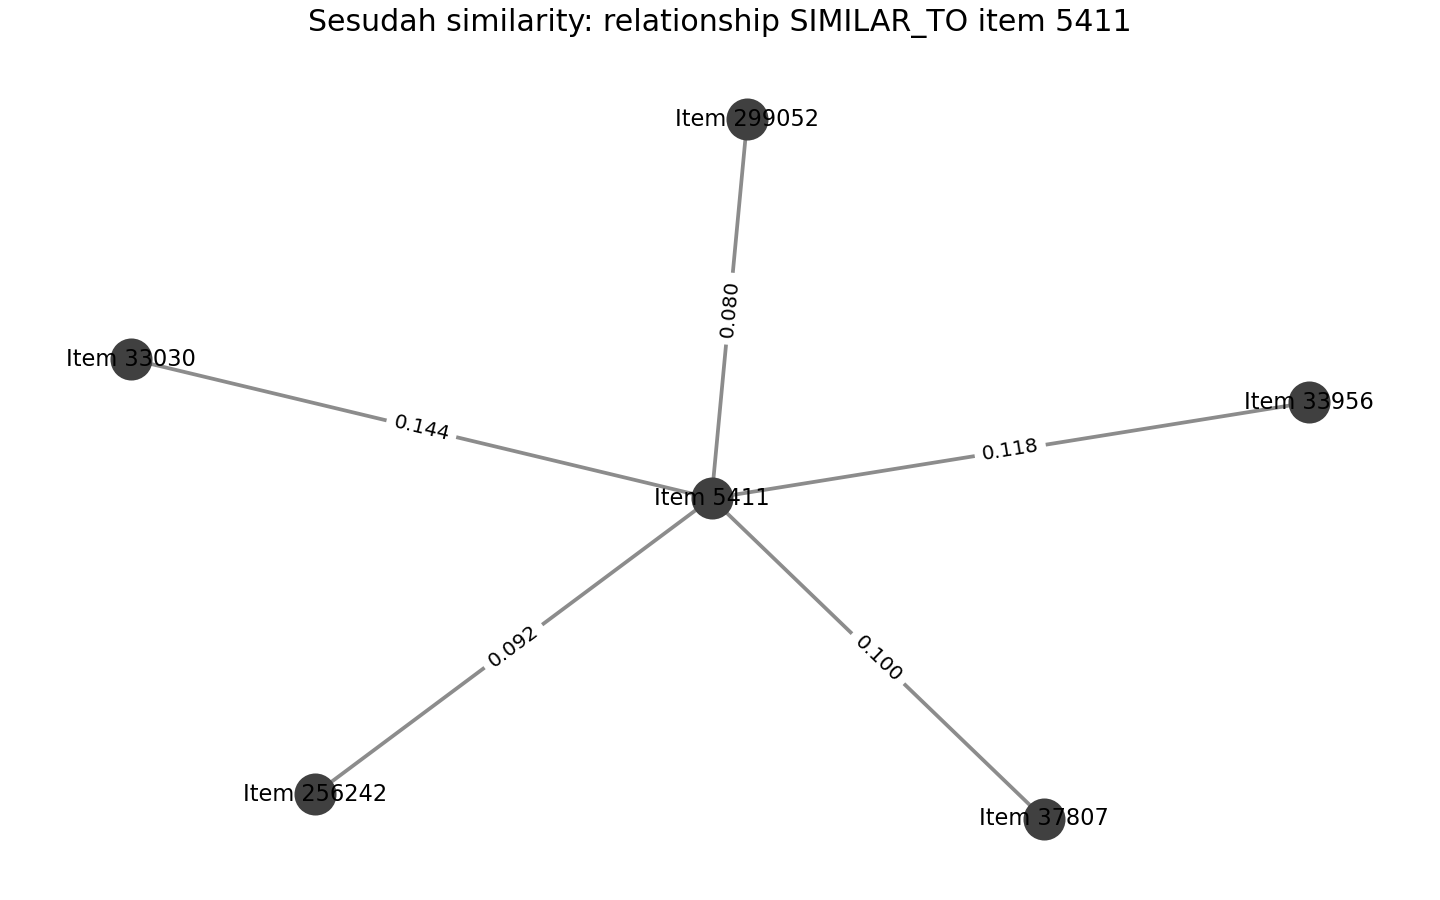

In [10]:
from IPython.display import Image, display
display(Image(filename='output/05_graph_sesudah_similarity.png'))

## 8. Rekomendasi KNN dan evaluasi
User dipilih dengan seed `23031554004`, sehingga pilihan acak dapat direproduksi. KNN memakai lima user tetangga terdekat.

In [11]:
print(pd.read_csv(OUTPUT_DIR / 'knn_neighbors.csv').to_string(index=False))
print()
print(pd.read_csv(OUTPUT_DIR / 'top5_recommendations.csv').to_string(index=False))
print()
print('Hit@5:', summary['hit_at_5'])
print('NDCG@5:', summary['ndcg_at_5'])

KNN neighbor:
selected_user,neighbor_user,cosine_similarity
506200,764475,0.57735026
506200,1342290,0.49236596
506200,831799,0.43245083
506200,408723,0.40824828
506200,74145,0.40824828

Top-5 rekomendasi:
selected_user,rank,recommended_item,score,is_relevant_in_testing
506200,1,171143,1.29735255,False
506200,2,189288,1.29735255,False
506200,3,151586,0.86490166,False
506200,4,89658,0.57735026,False
506200,5,19761,0.49236596,False

Hit@5: 0.0
NDCG@5: 0.0


**Interpretasi:** tidak ada item relevan testing yang masuk ke Top-5 user acak ini. Nilai Hit@5 dan NDCG@5 sama-sama nol, yang menunjukkan baseline KNN masih perlu pengembangan untuk data RetailRocket yang sparse.

## 9. Neo4j
Source impor batch dan query Cypher tersedia pada appendix. Setelah mengatur kredensial Neo4j, jalankan `neo4j_import_filtered.py` lalu gunakan query untuk menampilkan graph sebelum dan sesudah relationship `SIMILAR_TO` dibuat.

In [12]:
print('CYPHER QUERY:\n')
print(open('neo4j_uts_queries.cypher', encoding='utf-8').read())

// Jalankan setelah events_training_2015-05-01_2015-07-20.csv diimpor.

// 1. Komposisi subgraph dan jenis relationship.
MATCH (n)
RETURN labels(n) AS node_type, count(n) AS jumlah_node
ORDER BY jumlah_node DESC;

MATCH ()-[r]->()
RETURN type(r) AS relationship_type, count(r) AS jumlah_relationship
ORDER BY jumlah_relationship DESC;

// 2. Tampilan graph sebelum similarity, dibatasi agar Neo4j Browser tetap ringan.
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v, r, i
LIMIT 100;

// 3. Ambil lima item paling mirip dari satu item acuan.
// Ganti nilai parameter reference_item_id sesuai output/top5_item_similarity.csv.
MATCH (source:Item {itemId: $reference_item_id})-[s:SIMILAR_TO]->(candidate:Item)
RETURN source.itemId AS item_acuan, candidate.itemId AS item_mirip, s.score AS cosine_similarity
ORDER BY s.score DESC
LIMIT 5;

// 4. Tulis nilai similarity pada graph. $rows berbentuk list map
// contoh: [{source: 123, target: 456, score: 0.87}, ...]
UNWIND $rows AS row

## Appendix A. Source code analisis
Cell berikut adalah source lengkap yang menjalankan wrangling, VSM, similarity, KNN, dan evaluasi.

In [ ]:
"""Analisis UTS Graf Sains Data, RetailRocket, Kristian Bintang.

Fold training: 2015-05-01 s.d. 2015-07-20 UTC
Fold testing : 2015-07-21 s.d. 2015-08-10 UTC

"""

from __future__ import annotations

import csv
import argparse
import json
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix, csr_matrix


NAMA = "Kristian Bintang Marnaek Hutapea"
NIM = "23031554004"
SEED = 23031554004
LAYOUT_SEED = SEED % (2**32)
TRAIN_START = pd.Timestamp("2015-05-01", tz="UTC")
TRAIN_END_EXCLUSIVE = pd.Timestamp("2015-07-21", tz="UTC")
TEST_START = pd.Timestamp("2015-07-21", tz="UTC")
TEST_END_EXCLUSIVE = pd.Timestamp("2015-08-11", tz="UTC")
EVENT_WEIGHT = {"view": 1.0, "addtocart": 3.0, "transaction": 5.0}

BASE_DIR = Path(__file__).resolve().parent
DATA_PATH = BASE_DIR / "data" / "events.csv"
OUTPUT_DIR = BASE_DIR / "output"


def load_events() -> pd.DataFrame:
    """Baca data RetailRocket dan buat waktu UTC dari Unix epoch milliseconds."""
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"{DATA_PATH} tidak ditemukan. Unduh events.csv RetailRocket terlebih dahulu."
        )
    events = pd.read_csv(
        DATA_PATH,
        dtype={
            "timestamp": "int64",
            "visitorid": "int32",
            "event": "category",
            "itemid": "int32",
            "transactionid": "string",
        },
    )
    events["timestamp_utc"] = pd.to_datetime(events["timestamp"], unit="ms", utc=True)
    return events


def split_folds(events: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    training = events[
        (events["timestamp_utc"] >= TRAIN_START)
        & (events["timestamp_utc"] < TRAIN_END_EXCLUSIVE)
    ].copy()
    testing = events[
        (events["timestamp_utc"] >= TEST_START)
        & (events["timestamp_utc"] < TEST_END_EXCLUSIVE)
    ].copy()
    return training, testing


def save_folds(training: pd.DataFrame, testing: pd.DataFrame) -> None:
    columns = ["timestamp", "timestamp_utc", "visitorid", "event", "itemid", "transactionid"]
    training[columns].to_csv(OUTPUT_DIR / "events_training_2015-05-01_2015-07-20.csv", index=False)
    testing[columns].to_csv(OUTPUT_DIR / "events_testing_2015-07-21_2015-08-10.csv", index=False)


def build_interaction_matrix(events: pd.DataFrame) -> tuple[csr_matrix, np.ndarray, np.ndarray, pd.DataFrame]:
    weighted = events[["visitorid", "itemid", "event"]].copy()
    weighted["weight"] = weighted["event"].astype(str).map(EVENT_WEIGHT).astype("float32")
    interactions = (
        weighted.groupby(["visitorid", "itemid"], as_index=False, observed=True)["weight"]
        .sum()
    )
    user_ids = np.sort(interactions["visitorid"].unique())
    item_ids = np.sort(interactions["itemid"].unique())
    user_index = pd.Index(user_ids)
    item_index = pd.Index(item_ids)
    rows = user_index.get_indexer(interactions["visitorid"])
    columns = item_index.get_indexer(interactions["itemid"])
    matrix = coo_matrix(
        (interactions["weight"].to_numpy(), (rows, columns)),
        shape=(len(user_ids), len(item_ids)),
        dtype=np.float32,
    ).tocsr()
    return matrix, user_ids, item_ids, interactions


def normalize_rows(matrix: csr_matrix) -> csr_matrix:
    norms = np.sqrt(matrix.multiply(matrix).sum(axis=1)).A1
    norms[norms == 0] = 1.0
    return matrix.multiply(1.0 / norms[:, None]).tocsr()


def calculate_vsm_summary(interactions: pd.DataFrame, matrix: csr_matrix) -> dict:
    unique_pairs = interactions[["visitorid", "itemid"]].drop_duplicates()
    user_degree = unique_pairs.groupby("visitorid").size()
    item_degree = unique_pairs.groupby("itemid").size()
    user_projection_candidates = int((item_degree * (item_degree - 1) // 2).sum())
    item_projection_candidates = int((user_degree * (user_degree - 1) // 2).sum())
    return {
        "user_vsm_shape": [int(matrix.shape[0]), int(matrix.shape[1])],
        "item_vsm_shape": [int(matrix.shape[1]), int(matrix.shape[0])],
        "nonzero_user_item_pairs": int(matrix.nnz),
        "density": float(matrix.nnz / (matrix.shape[0] * matrix.shape[1])),
        "mean_user_degree": float(user_degree.mean()),
        "median_user_degree": float(user_degree.median()),
        "max_user_degree": int(user_degree.max()),
        "mean_item_degree": float(item_degree.mean()),
        "median_item_degree": float(item_degree.median()),
        "max_item_degree": int(item_degree.max()),
        "candidate_user_projection_edges": user_projection_candidates,
        "candidate_item_projection_edges": item_projection_candidates,
        "recommended_projection": "item",
        "reason": (
            "Proyeksi item dipilih karena menghasilkan kandidat pasangan lebih sedikit "
            "daripada proyeksi user pada data training ini."
        ),
    }


def plot_event_distribution(training: pd.DataFrame, testing: pd.DataFrame) -> None:
    labels = ["view", "addtocart", "transaction"]
    training_counts = training["event"].astype(str).value_counts().reindex(labels, fill_value=0)
    testing_counts = testing["event"].astype(str).value_counts().reindex(labels, fill_value=0)
    x = np.arange(len(labels))
    figure, axis = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
    axis.bar(x - 0.18, training_counts.values, 0.36, label="Training", color="0.25")
    axis.bar(x + 0.18, testing_counts.values, 0.36, label="Testing", color="0.65")
    axis.set_xticks(x, labels)
    axis.set_ylabel("Jumlah event")
    axis.set_title("Komposisi event RetailRocket per fold")
    axis.legend()
    axis.grid(axis="y", alpha=0.25)
    figure.savefig(OUTPUT_DIR / "01_komposisi_event.png", dpi=180)
    plt.close(figure)


def plot_user_vsm_sample(interactions: pd.DataFrame) -> None:
    user_activity = interactions.groupby("visitorid")["itemid"].nunique().nlargest(12)
    sample = interactions[interactions["visitorid"].isin(user_activity.index)]
    top_items = sample.groupby("itemid")["visitorid"].nunique().nlargest(30).index
    sample = sample[sample["itemid"].isin(top_items)]
    graph = nx.Graph()
    graph.add_nodes_from([f"U{value}" for value in sample["visitorid"].unique()], kind="user")
    graph.add_nodes_from([f"I{value}" for value in sample["itemid"].unique()], kind="item")
    graph.add_edges_from((f"U{row.visitorid}", f"I{row.itemid}") for row in sample.itertuples())
    position = nx.spring_layout(graph, seed=LAYOUT_SEED, k=0.75)
    figure, axis = plt.subplots(figsize=(11, 7), constrained_layout=True)
    user_nodes = [node for node, data in graph.nodes(data=True) if data["kind"] == "user"]
    item_nodes = [node for node, data in graph.nodes(data=True) if data["kind"] == "item"]
    nx.draw_networkx_nodes(graph, position, nodelist=user_nodes, node_size=85, node_color="0.1", ax=axis)
    nx.draw_networkx_nodes(graph, position, nodelist=item_nodes, node_size=55, node_color="0.65", ax=axis)
    nx.draw_networkx_edges(graph, position, width=0.7, alpha=0.55, ax=axis)
    axis.set_title("Contoh graph bipartit user-item dari VSM user")
    axis.axis("off")
    figure.savefig(OUTPUT_DIR / "02_contoh_graph_bipartit_user_vsm.png", dpi=180)
    plt.close(figure)


def plot_item_projection_sample(matrix: csr_matrix, item_ids: np.ndarray, interactions: pd.DataFrame) -> None:
    """Visualisasi contoh proyeksi item-item dari user bersama."""
    selected_item_ids = interactions.groupby("itemid").size().nlargest(35).index.to_numpy()
    selected_indices = np.searchsorted(item_ids, selected_item_ids)
    binary_submatrix = matrix[:, selected_indices].copy()
    binary_submatrix.data = np.ones_like(binary_submatrix.data)
    cooccurrence = (binary_submatrix.T @ binary_submatrix).toarray()
    np.fill_diagonal(cooccurrence, 0)

    graph = nx.Graph()
    graph.add_nodes_from(int(item) for item in selected_item_ids)
    for left in range(len(selected_item_ids)):
        for right in range(left + 1, len(selected_item_ids)):
            if cooccurrence[left, right] > 0:
                graph.add_edge(
                    int(selected_item_ids[left]),
                    int(selected_item_ids[right]),
                    weight=int(cooccurrence[left, right]),
                )
    # Isolat tidak memberi informasi hubungan co-occurence pada gambar proyeksi.
    graph.remove_nodes_from(list(nx.isolates(graph)))
    position = nx.spring_layout(graph, seed=LAYOUT_SEED, weight="weight")
    figure, axis = plt.subplots(figsize=(10, 7), constrained_layout=True)
    edge_width = [0.35 + np.log1p(data["weight"]) * 0.25 for _, _, data in graph.edges(data=True)]
    nx.draw_networkx_nodes(graph, position, node_size=100, node_color="0.25", ax=axis)
    nx.draw_networkx_edges(graph, position, width=edge_width, alpha=0.5, edge_color="0.55", ax=axis)
    axis.set_title("Contoh proyeksi item-item dari VSM item")
    axis.axis("off")
    figure.savefig(OUTPUT_DIR / "03_contoh_proyeksi_item_vsm.png", dpi=180)
    plt.close(figure)


def item_similarity(
    matrix: csr_matrix, item_ids: np.ndarray, interactions: pd.DataFrame
) -> tuple[int, list[tuple[int, float]]]:
    """Cari lima item paling mirip memakai cosine similarity pada item VSM."""
    item_matrix = matrix.T.tocsr()
    normalized_items = normalize_rows(item_matrix)
    item_counts = interactions.groupby("itemid").size().sort_values(ascending=False)
    reference_item = int(item_counts.index[0])
    reference_index = int(np.searchsorted(item_ids, reference_item))
    # Kandidat hanya item yang pernah berinteraksi dengan user yang sama.
    # Item lain memiliki dot-product 0 sehingga tidak dapat masuk Top-5.
    target_vector = normalized_items.getrow(reference_index)
    target_users = target_vector.indices
    candidate_indices = np.unique(matrix[target_users].indices)
    candidate_scores = (normalized_items[candidate_indices] @ target_vector.T).toarray().ravel()
    candidate_scores[candidate_indices == reference_index] = -1.0
    selected_order = np.argpartition(candidate_scores, -5)[-5:]
    selected_order = selected_order[np.argsort(candidate_scores[selected_order])[::-1]]
    result = [
        (int(item_ids[candidate_indices[index]]), float(candidate_scores[index]))
        for index in selected_order
    ]
    return reference_item, result


def plot_similarity_before_after(
    reference_item: int, similar_items: list[tuple[int, float]], interactions: pd.DataFrame
) -> None:
    connected_users = (
        interactions.loc[interactions["itemid"] == reference_item]
        .sort_values("weight", ascending=False)
        .head(15)
    )
    before_graph = nx.Graph()
    reference_node = f"Item {reference_item}"
    before_graph.add_node(reference_node, kind="item")
    for row in connected_users.itertuples():
        visitor_node = f"Visitor {row.visitorid}"
        before_graph.add_node(visitor_node, kind="visitor")
        before_graph.add_edge(visitor_node, reference_node)
    before_position = nx.spring_layout(before_graph, seed=LAYOUT_SEED)
    figure, axis = plt.subplots(figsize=(8, 5), constrained_layout=True)
    visitors = [node for node, data in before_graph.nodes(data=True) if data["kind"] == "visitor"]
    nx.draw_networkx_nodes(before_graph, before_position, nodelist=visitors, node_size=110, node_color="0.65", ax=axis)
    nx.draw_networkx_nodes(before_graph, before_position, nodelist=[reference_node], node_size=280, node_color="0.1", ax=axis)
    nx.draw_networkx_edges(before_graph, before_position, width=1.0, alpha=0.65, ax=axis)
    nx.draw_networkx_labels(before_graph, before_position, labels={reference_node: reference_node}, font_size=9, ax=axis)
    axis.set_title("Sebelum similarity: hubungan Visitor ke Item 5411")
    axis.axis("off")
    figure.savefig(OUTPUT_DIR / "04_graph_sebelum_similarity.png", dpi=180)
    plt.close(figure)

    after_graph = nx.Graph()
    after_graph.add_node(reference_node)
    for item, score in similar_items:
        item_node = f"Item {item}"
        after_graph.add_node(item_node)
        after_graph.add_edge(reference_node, item_node, score=score)
    after_position = nx.spring_layout(after_graph, seed=LAYOUT_SEED)
    figure, axis = plt.subplots(figsize=(8, 5), constrained_layout=True)
    nx.draw_networkx_nodes(after_graph, after_position, node_size=250, node_color="0.25", ax=axis)
    nx.draw_networkx_edges(after_graph, after_position, width=1.5, edge_color="0.55", ax=axis)
    nx.draw_networkx_labels(after_graph, after_position, font_size=9, ax=axis)
    edge_labels = {(left, right): f"{data['score']:.3f}" for left, right, data in after_graph.edges(data=True)}
    nx.draw_networkx_edge_labels(after_graph, after_position, edge_labels=edge_labels, font_size=8, ax=axis)
    axis.set_title("Sesudah similarity: relationship SIMILAR_TO item 5411")
    axis.axis("off")
    figure.savefig(OUTPUT_DIR / "05_graph_sesudah_similarity.png", dpi=180)
    plt.close(figure)


def choose_user_and_recommend(
    matrix: csr_matrix,
    user_ids: np.ndarray,
    item_ids: np.ndarray,
    training: pd.DataFrame,
    testing: pd.DataFrame,
) -> tuple[int, list[tuple[int, float]], list[tuple[int, float]], float, float, set[int]]:
    unique_pairs = training[["visitorid", "itemid"]].drop_duplicates()
    train_degree = unique_pairs.groupby("visitorid").size()
    # User harus memiliki minimal satu item yang juga dilihat user lain.
    # Tanpa syarat ini seluruh cosine similarity ke user lain pasti nol.
    shared_item_ids = set(
        unique_pairs.groupby("itemid")["visitorid"].size().loc[lambda count: count >= 2].index.astype(int)
    )
    users_with_shared_item = set(
        training.loc[training["itemid"].isin(shared_item_ids), "visitorid"].astype(int).unique()
    )
    test_user_ids = set(testing["visitorid"].astype(int).unique())
    eligible = np.array(
        [
            int(user)
            for user in train_degree[train_degree >= 2].index
            if user in users_with_shared_item and user in test_user_ids
        ],
        dtype=np.int64,
    )
    if eligible.size == 0:
        raise RuntimeError("Tidak ada user yang memenuhi syarat evaluasi temporal.")
    rng = np.random.default_rng(SEED)
    normalized_users = normalize_rows(matrix)
    # Acak secara reproducible. Selain mempunyai item testing baru, user harus
    # menghasilkan kandidat rekomendasi berskor positif dari lima KNN-nya.
    selected_user = None
    neighbors: list[tuple[int, float]] = []
    recommendations: list[tuple[int, float]] = []
    relevant_items: set[int] = set()
    for candidate in rng.permutation(eligible):
        seen_candidate = set(training.loc[training["visitorid"] == candidate, "itemid"].astype(int))
        relevant_candidate = set(testing.loc[testing["visitorid"] == candidate, "itemid"].astype(int)) - seen_candidate
        if not relevant_candidate:
            continue
        candidate_index = int(np.searchsorted(user_ids, candidate))
        target_vector = normalized_users.getrow(candidate_index)
        target_items = target_vector.indices
        knn_candidate_indices = np.unique(matrix[:, target_items].nonzero()[0])
        if len(knn_candidate_indices) <= 5:
            continue
        knn_scores = (normalized_users[knn_candidate_indices] @ target_vector.T).toarray().ravel()
        knn_scores[knn_candidate_indices == candidate_index] = -1.0
        knn_order = np.argpartition(knn_scores, -5)[-5:]
        knn_order = knn_order[np.argsort(knn_scores[knn_order])[::-1]]
        neighbor_indices = knn_candidate_indices[knn_order]
        neighbor_weight = knn_scores[knn_order].astype(np.float32)
        candidate_recommendation_scores = matrix[neighbor_indices].T.dot(neighbor_weight).ravel()
        candidate_recommendation_scores[np.searchsorted(item_ids, list(seen_candidate))] = -np.inf
        positive_recommendation_indices = np.flatnonzero(candidate_recommendation_scores > 0)
        if len(positive_recommendation_indices) < 5:
            continue
        recommendation_order = positive_recommendation_indices[
            np.argsort(candidate_recommendation_scores[positive_recommendation_indices])[::-1][:5]
        ]
        selected_user = int(candidate)
        relevant_items = relevant_candidate
        neighbors = [
            (int(user_ids[index]), float(knn_scores[order]))
            for index, order in zip(neighbor_indices, knn_order)
        ]
        recommendations = [
            (int(item_ids[index]), float(candidate_recommendation_scores[index]))
            for index in recommendation_order
        ]
        break
    if selected_user is None:
        raise RuntimeError("Tidak ada user acak dengan kandidat rekomendasi positif.")
    relevant_flags = [item_id in relevant_items for item_id, _ in recommendations]
    hit_at_5 = float(any(relevant_flags))
    dcg = sum(1.0 / np.log2(rank + 2) for rank, is_relevant in enumerate(relevant_flags) if is_relevant)
    ideal_count = min(len(relevant_items), 5)
    idcg = sum(1.0 / np.log2(rank + 2) for rank in range(ideal_count))
    ndcg_at_5 = float(dcg / idcg) if idcg else 0.0
    return selected_user, neighbors, recommendations, hit_at_5, ndcg_at_5, relevant_items


def save_table(path: Path, rows: list[dict], columns: list[str]) -> None:
    with path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)


def write_report(summary: dict, selected_user: int, reference_item: int) -> None:
    report = f"""# UTS Graf Sains Data

Nama: {NAMA}  
NIM: {NIM}

## Pembagian data

Timestamp RetailRocket dikonversi dari Unix epoch milliseconds ke UTC. Fold training memakai interval [{TRAIN_START.date()}, {TRAIN_END_EXCLUSIVE.date()}) dan fold testing memakai interval [{TEST_START.date()}, {TEST_END_EXCLUSIVE.date()}). Batas akhir eksklusif mencegah satu event masuk ke dua fold.

Training berisi {summary['training_events']:,} event, {summary['training_users']:,} visitor, dan {summary['training_items']:,} item. Testing berisi {summary['testing_events']:,} event, {summary['testing_users']:,} visitor, dan {summary['testing_items']:,} item.

## Komposisi subgraph

Subgraph training memiliki dua jenis simpul, yaitu `Visitor` dan `Item`. Hubungan dibentuk dari event `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Komposisinya ada pada `summary.json` dan grafik `01_komposisi_event.png`.

## VSM dan proyeksi

VSM user berbentuk {summary['vsm']['user_vsm_shape'][0]:,} x {summary['vsm']['user_vsm_shape'][1]:,}. Setiap baris mewakili visitor dan setiap kolom mewakili item. VSM item adalah transposenya, yaitu {summary['vsm']['item_vsm_shape'][0]:,} x {summary['vsm']['item_vsm_shape'][1]:,}.

Proyeksi item dipilih karena jumlah kandidat edge item-item ({summary['vsm']['candidate_item_projection_edges']:,}) lebih rendah daripada kandidat edge user-user ({summary['vsm']['candidate_user_projection_edges']:,}). Dengan demikian proyeksi item lebih efisien untuk similarity pada data ini.

## Similarity dan rekomendasi

Item acuan similarity adalah {reference_item}. Lima item mirip beserta skor cosine tersimpan pada `top5_item_similarity.csv`. User untuk KNN dipilih acak secara reproducible menggunakan seed {SEED}, yaitu visitor {selected_user}. Lima tetangga terdekat, Top-5 rekomendasi, Hit@5, dan NDCG@5 tersimpan pada `knn_recommendation_evaluation.json`.

## Catatan Neo4j

File `neo4j_import_filtered.py` mengimpor file fold training ke Neo4j secara batch. File `neo4j_uts_queries.cypher` berisi CYPHER untuk komposisi subgraph, kondisi sebelum dan sesudah similarity, lima similarity tertinggi, dan penyimpanan relationship `SIMILAR_TO`.
"""
    (OUTPUT_DIR / "laporan_ringkas_uts.md").write_text(report, encoding="utf-8")


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument(
        "--use-existing-folds",
        action="store_true",
        help="Lewati pembacaan raw events.csv dan gunakan CSV fold yang sudah dibuat.",
    )
    args = parser.parse_args()
    OUTPUT_DIR.mkdir(exist_ok=True)
    training_path = OUTPUT_DIR / "events_training_2015-05-01_2015-07-20.csv"
    testing_path = OUTPUT_DIR / "events_testing_2015-07-21_2015-08-10.csv"
    if args.use_existing_folds:
        if not training_path.exists() or not testing_path.exists():
            raise FileNotFoundError("CSV fold belum ada. Jalankan tanpa --use-existing-folds terlebih dahulu.")
        training = pd.read_csv(training_path, dtype={"visitorid": "int32", "itemid": "int32", "event": "category"})
        testing = pd.read_csv(testing_path, dtype={"visitorid": "int32", "itemid": "int32", "event": "category"})
    else:
        events = load_events()
        training, testing = split_folds(events)
        save_folds(training, testing)

    matrix, user_ids, item_ids, interactions = build_interaction_matrix(training)
    vsm = calculate_vsm_summary(interactions, matrix)
    plot_event_distribution(training, testing)
    plot_user_vsm_sample(interactions)
    plot_item_projection_sample(matrix, item_ids, interactions)

    reference_item, similar_items = item_similarity(matrix, item_ids, interactions)
    plot_similarity_before_after(reference_item, similar_items, interactions)
    selected_user, neighbors, recommendations, hit_at_5, ndcg_at_5, relevant_items = choose_user_and_recommend(
        matrix, user_ids, item_ids, training, testing
    )
    save_table(
        OUTPUT_DIR / "top5_item_similarity.csv",
        [{"reference_item": reference_item, "similar_item": item, "cosine_similarity": round(score, 8)} for item, score in similar_items],
        ["reference_item", "similar_item", "cosine_similarity"],
    )
    save_table(
        OUTPUT_DIR / "knn_neighbors.csv",
        [{"selected_user": selected_user, "neighbor_user": user, "cosine_similarity": round(score, 8)} for user, score in neighbors],
        ["selected_user", "neighbor_user", "cosine_similarity"],
    )
    save_table(
        OUTPUT_DIR / "top5_recommendations.csv",
        [
            {
                "selected_user": selected_user,
                "rank": rank,
                "recommended_item": item,
                "score": round(score, 8),
                "is_relevant_in_testing": item in relevant_items,
            }
            for rank, (item, score) in enumerate(recommendations, start=1)
        ],
        ["selected_user", "rank", "recommended_item", "score", "is_relevant_in_testing"],
    )

    summary = {
        "student": {"name": NAMA, "nim": NIM},
        "time_basis": "UTC",
        "training_period": [str(TRAIN_START.date()), "2015-07-20"],
        "testing_period": [str(TEST_START.date()), "2015-08-10"],
        "training_events": int(len(training)),
        "testing_events": int(len(testing)),
        "training_users": int(training["visitorid"].nunique()),
        "training_items": int(training["itemid"].nunique()),
        "testing_users": int(testing["visitorid"].nunique()),
        "testing_items": int(testing["itemid"].nunique()),
        "training_event_composition": {key: int(value) for key, value in training["event"].astype(str).value_counts().items()},
        "testing_event_composition": {key: int(value) for key, value in testing["event"].astype(str).value_counts().items()},
        "vsm": vsm,
        "similarity_reference_item": reference_item,
        "selected_user": selected_user,
        "knn_k": 5,
        "advertised_top3_items": [item for item, _ in recommendations[:3]],
        "hit_at_5": hit_at_5,
        "ndcg_at_5": ndcg_at_5,
    }
    (OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    evaluation = {
        "selected_user": selected_user,
        "selection_method": f"np.random.default_rng({SEED}) over eligible users with train history and unseen test interactions",
        "knn_k": 5,
        "relevant_unseen_test_items": sorted(relevant_items),
        "recommendations_top5": [{"itemid": item, "score": score} for item, score in recommendations],
        "hit_at_5": hit_at_5,
        "ndcg_at_5": ndcg_at_5,
    }
    (OUTPUT_DIR / "knn_recommendation_evaluation.json").write_text(json.dumps(evaluation, indent=2), encoding="utf-8")
    write_report(summary, selected_user, reference_item)
    print(json.dumps(summary, indent=2))
    print(f"Output tersimpan di: {OUTPUT_DIR}")


if __name__ == "__main__":
    main()


## Appendix B. Source code impor Neo4j

In [ ]:


from __future__ import annotations

import os
from pathlib import Path

import pandas as pd
from neo4j import GraphDatabase


BASE_DIR = Path(__file__).resolve().parent
CSV_PATH = BASE_DIR / "output" / "events_training_2015-05-01_2015-07-20.csv"
BATCH_SIZE = 10_000


def create_constraints(session) -> None:
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")


def import_batch(tx, rows) -> None:
    query = """
    UNWIND $rows AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
      WITH v, i, row WHERE row.event = 'view'
      MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
      RETURN count(*) AS ignored
      UNION
      WITH v, i, row WHERE row.event = 'addtocart'
      MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
      RETURN count(*) AS ignored
      UNION
      WITH v, i, row WHERE row.event = 'transaction'
      MERGE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
      RETURN count(*) AS ignored
    }
    RETURN count(*) AS imported
    """
    tx.run(query, rows=rows).consume()


def main() -> None:
    if not CSV_PATH.exists():
        raise FileNotFoundError("Jalankan run_uts_analysis.py terlebih dahulu.")
    uri = os.environ.get("NEO4J_URI")
    user = os.environ.get("NEO4J_USER")
    password = os.environ.get("NEO4J_PASSWORD")
    if not all([uri, user, password]):
        raise RuntimeError("NEO4J_URI, NEO4J_USER, dan NEO4J_PASSWORD harus diisi sebagai environment variable.")
    with GraphDatabase.driver(uri, auth=(user, password)) as driver:
        driver.verify_connectivity()
        with driver.session() as session:
            create_constraints(session)
            for number, chunk in enumerate(pd.read_csv(CSV_PATH, chunksize=BATCH_SIZE), start=1):
                chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
                session.execute_write(import_batch, chunk.to_dict(orient="records"))
                print(f"Batch {number} selesai, {len(chunk):,} baris.")
    print("Impor Neo4j selesai.")


if __name__ == "__main__":
    main()
